# Bike-share Trip Clustering

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Find patterns or groups in urban bike-share trip records.

**Approach:** Data preparation, DBSCAN clustering and visualization.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Clustering </span>
    </span>
    </center>
<br>
<h1>By GUERBOUZ MOHAMMED ALAA EDDINE</h1>

In [9]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt

# Load the dataset
file_path = r"citibike-tripdata.csv"  # Replace with the path to your file
data = pd.read_csv(file_path)

# Display dataset information
print("Dataset Head:\n", data.head())
print("Columns:\n", data.columns)

# Data Preprocessing
# Handle missing values (fill with mean/mode or drop)
data = data.dropna()

# Encode categorical columns (except gender, as it is already encoded)
categorical_cols = ['usertype', 'start station name', 'end station name']
for col in categorical_cols:
    encoder = LabelEncoder()
    data[col] = encoder.fit_transform(data[col])

# Convert temporal columns to numerical (e.g., starttime and stoptime)
data['starttime'] = pd.to_datetime(data['starttime'])
data['stoptime'] = pd.to_datetime(data['stoptime'])

data['trip_start_hour'] = data['starttime'].dt.hour
data['trip_end_hour'] = data['stoptime'].dt.hour
data['trip_duration'] = (data['stoptime'] - data['starttime']).dt.total_seconds()

# Drop the original datetime columns (if not needed)
data = data.drop(['starttime', 'stoptime'], axis=1)

# Normalize numerical data for clustering
numerical_cols = ['tripduration', 'start station latitude', 'start station longitude',
                  'end station latitude', 'end station longitude', 'birth year', 
                  'trip_start_hour', 'trip_end_hour', 'trip_duration']
scaler = StandardScaler()
data[numerical_cols] = scaler.fit_transform(data[numerical_cols])




Dataset Head:
    tripduration                 starttime                  stoptime  \
0           316  2019-06-01 00:05:55.7210  2019-06-01 00:11:11.9940   
1           280  2019-06-01 00:08:09.0920  2019-06-01 00:12:50.0730   
2          2162  2019-06-01 00:13:11.8800  2019-06-01 00:49:14.3640   
3          2184  2019-06-01 00:13:30.1110  2019-06-01 00:49:54.2250   
4           139  2019-06-01 00:13:31.8520  2019-06-01 00:15:51.7880   

   start station id start station name  start station latitude  \
0              3187          Warren St               40.721124   
1              3185          City Hall               40.717732   
2              3199       Newport Pkwy               40.728745   
3              3199       Newport Pkwy               40.728745   
4              3207        Oakland Ave               40.737604   

   start station longitude  end station id end station name  \
0               -74.038051            3199     Newport Pkwy   
1               -74.043845         

In [10]:
# Apply DBSCAN
dbscan = DBSCAN(eps=1.5, min_samples=5)  # Adjust eps and min_samples for better results
data['Cluster'] = dbscan.fit_predict(data)

# Analyze Clusters
print(data['Cluster'].value_counts())


Cluster
-1     38833
 39       25
 4        13
 21       12
 8        12
       ...  
 96        5
 83        5
 53        4
 95        4
 88        3
Name: count, Length: 99, dtype: int64


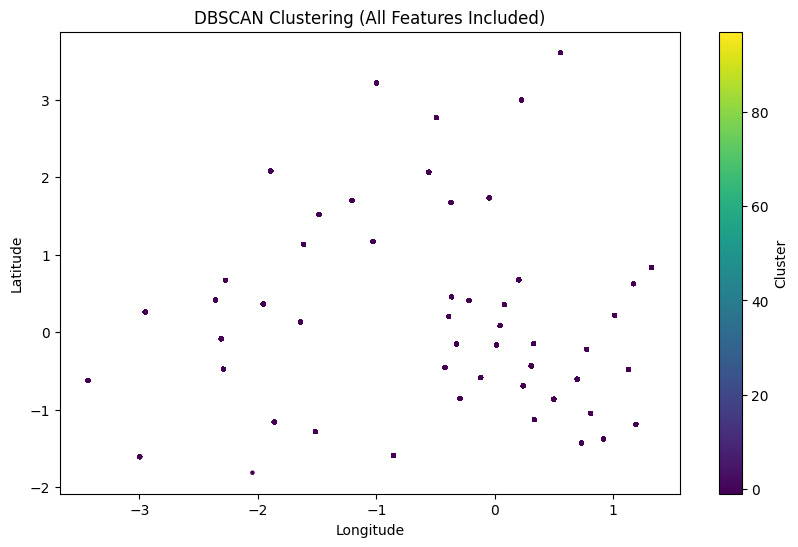

Clustered data saved to clustered_data_full_features.csv


In [11]:
# Visualization (if latitude and longitude are key features)
plt.figure(figsize=(10, 6))
plt.scatter(data['start station longitude'], 
            data['start station latitude'], 
            c=data['Cluster'], cmap='viridis', s=5)
plt.colorbar(label='Cluster')
plt.title('DBSCAN Clustering (All Features Included)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()
# Save clustered data to a CSV
output_file = 'clustered_data_full_features.csv'
data.to_csv(output_file, index=False)
print(f"Clustered data saved to {output_file}")

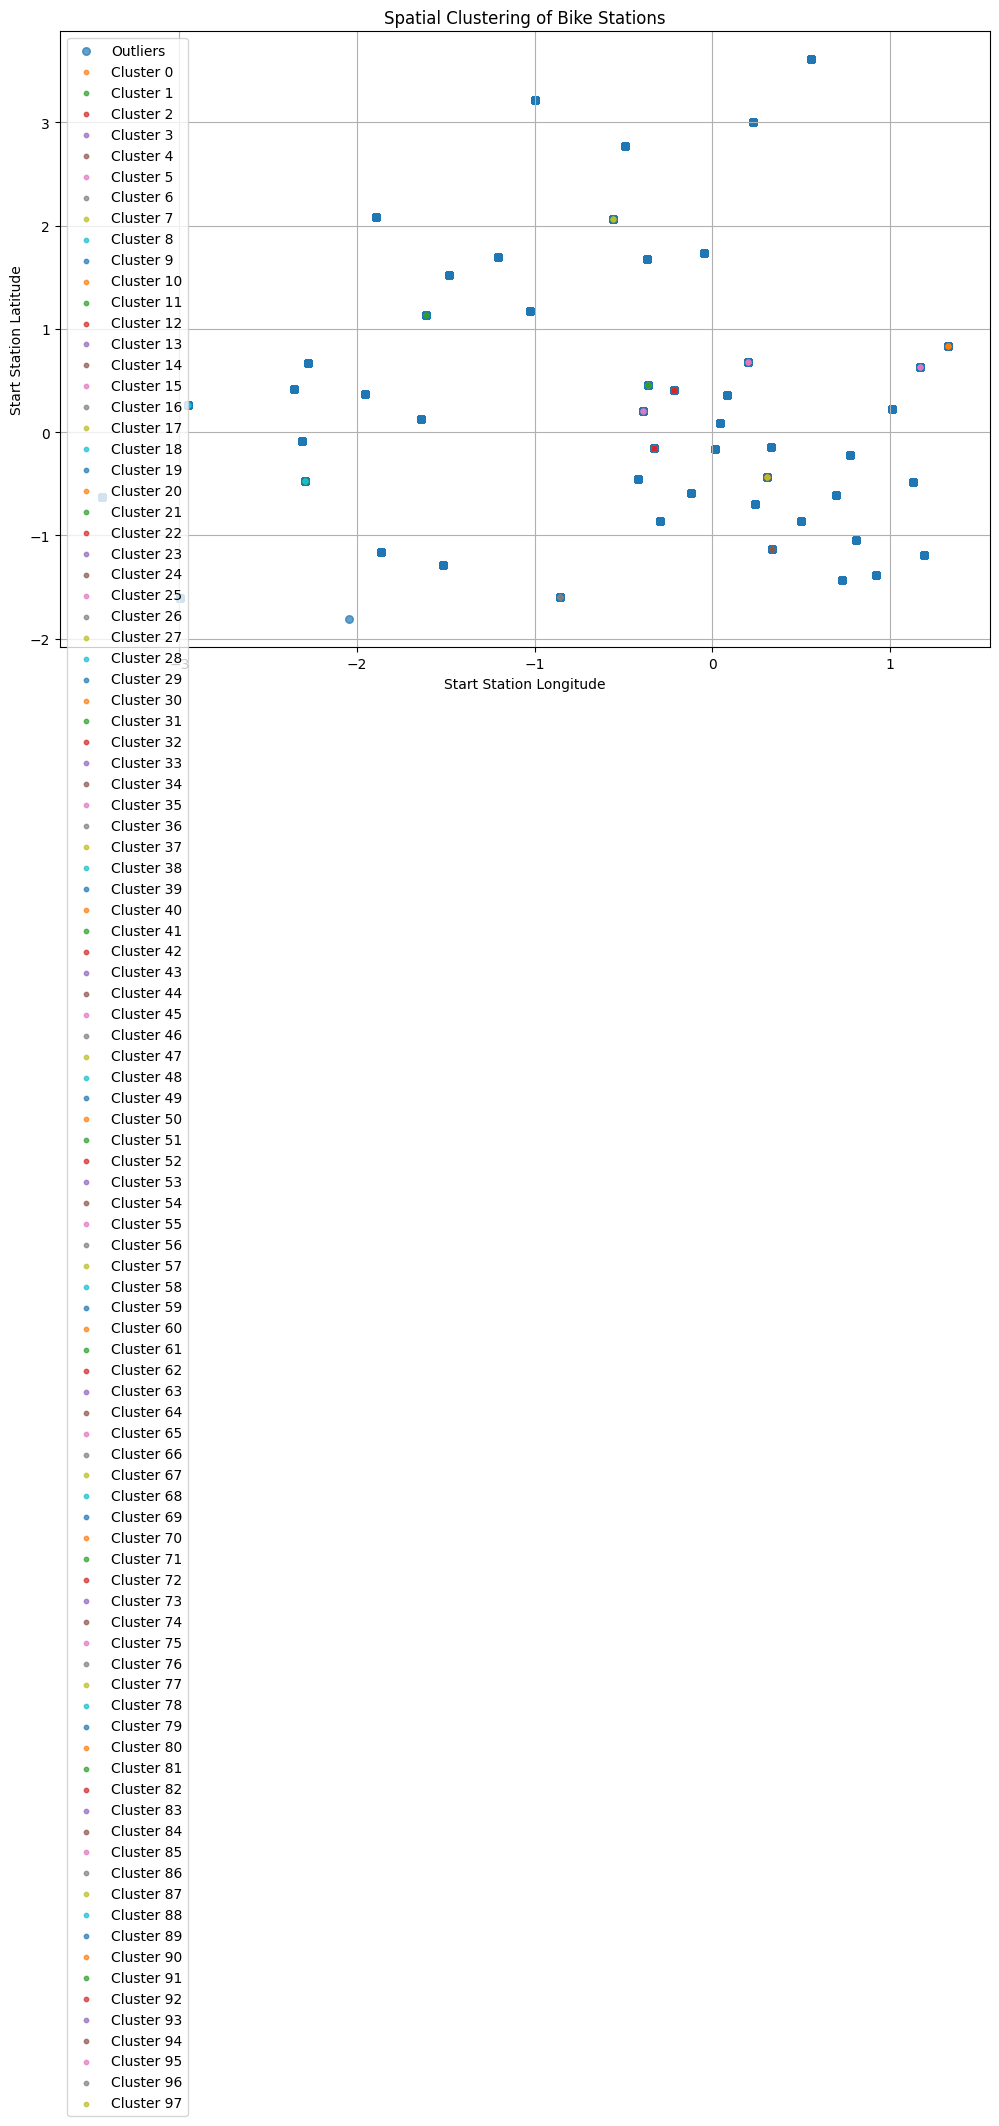

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Extract coordinates for plotting
longitude = data['start station longitude']
latitude = data['start station latitude']
clusters = data['Cluster']

# Initialize the plot
plt.figure(figsize=(12, 8))

# Scatter plot for each cluster
unique_clusters = np.unique(clusters)
for cluster in unique_clusters:
    cluster_data = data[data['Cluster'] == cluster]
    plt.scatter(cluster_data['start station longitude'],
                cluster_data['start station latitude'],
                label=f'Cluster {cluster}' if cluster != -1 else 'Outliers',
                s=10 if cluster != -1 else 30,  # Make outliers more prominent
                alpha=0.7)

# Title, labels, and legend
plt.title('Spatial Clustering of Bike Stations')
plt.xlabel('Start Station Longitude')
plt.ylabel('Start Station Latitude')
plt.legend()
plt.grid(True)
plt.show()


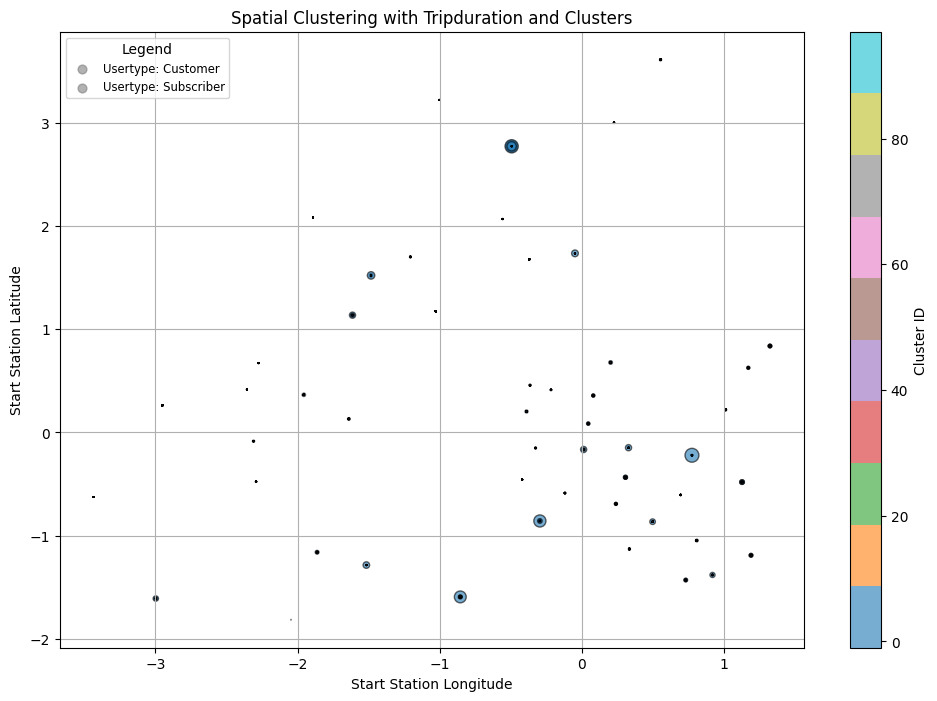

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Normalize tripduration for better visualization
data['scaled_tripduration'] = (data['tripduration'] - data['tripduration'].min()) / (
    data['tripduration'].max() - data['tripduration'].min()
)
data['scaled_tripduration'] = data['scaled_tripduration'] * 100  # Scale for marker size

# Extract necessary features for plotting
longitude = data['start station longitude']
latitude = data['start station latitude']
clusters = data['Cluster']
trip_durations = data['scaled_tripduration']
usertype = data['usertype']

# Create a scatter plot with tripduration as marker size
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    longitude,
    latitude,
    c=clusters,  # Use clusters for color coding
    s=trip_durations,  # Use trip duration for marker size
    alpha=0.6,
    cmap='tab10',  # Color map
    edgecolor='k'
)

# Add color bar and labels
plt.colorbar(scatter, label='Cluster ID')
plt.title('Spatial Clustering with Tripduration and Clusters')
plt.xlabel('Start Station Longitude')
plt.ylabel('Start Station Latitude')
plt.grid(True)

# Add a legend for usertype
usertype_labels = {0: "Subscriber", 1: "Customer"}
for user in usertype.unique():
    plt.scatter([], [], c='grey', alpha=0.6, s=40, label=f"Usertype: {usertype_labels.get(user, 'Unknown')}")

plt.legend(title="Legend", loc='best', fontsize='small')
plt.show()


In [14]:
# Get unique cluster labels
unique_clusters = data['Cluster'].unique()

# Count the total number of clusters (excluding -1 for outliers)
n_clusters = len(unique_clusters[unique_clusters != -1])

# Count the number of outliers
n_outliers = len(data[data['Cluster'] == -1])

print(f"Number of clusters (excluding outliers): {n_clusters}")
print(f"Number of outliers: {n_outliers}")

# Display the size of each cluster
cluster_counts = data['Cluster'].value_counts()
print("\nCluster Sizes:")
print(cluster_counts)


Number of clusters (excluding outliers): 98
Number of outliers: 38833

Cluster Sizes:
Cluster
-1     38833
 39       25
 4        13
 21       12
 8        12
       ...  
 96        5
 83        5
 53        4
 95        4
 88        3
Name: count, Length: 99, dtype: int64
